<a href="https://colab.research.google.com/github/A-I-eXplorers/ShimSoen/blob/main/Data_Preprocessing/Wine.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from sklearn.datasets import load_wine

wine = load_wine() # 데이터 불러오기

In [2]:
x, y = wine.data, wine.target
print(x.shape, y.shape)
print(wine.feature_names)
print(wine.target_names)

(178, 13) (178,)
['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline']
['class_0' 'class_1' 'class_2']


In [3]:
X, y = load_wine(return_X_y=True)

In [4]:
df = load_wine(as_frame=True).frame
print(df.head())

   alcohol  malic_acid   ash  alcalinity_of_ash  magnesium  total_phenols  \
0    14.23        1.71  2.43               15.6      127.0           2.80   
1    13.20        1.78  2.14               11.2      100.0           2.65   
2    13.16        2.36  2.67               18.6      101.0           2.80   
3    14.37        1.95  2.50               16.8      113.0           3.85   
4    13.24        2.59  2.87               21.0      118.0           2.80   

   flavanoids  nonflavanoid_phenols  proanthocyanins  color_intensity   hue  \
0        3.06                  0.28             2.29             5.64  1.04   
1        2.76                  0.26             1.28             4.38  1.05   
2        3.24                  0.30             2.81             5.68  1.03   
3        3.49                  0.24             2.18             7.80  0.86   
4        2.69                  0.39             1.82             4.32  1.04   

   od280/od315_of_diluted_wines  proline  target  
0          

# datatype 확인

In [5]:
print(df.dtypes)

alcohol                         float64
malic_acid                      float64
ash                             float64
alcalinity_of_ash               float64
magnesium                       float64
total_phenols                   float64
flavanoids                      float64
nonflavanoid_phenols            float64
proanthocyanins                 float64
color_intensity                 float64
hue                             float64
od280/od315_of_diluted_wines    float64
proline                         float64
target                            int64
dtype: object


# 결측치 확인

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 14 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   alcohol                       178 non-null    float64
 1   malic_acid                    178 non-null    float64
 2   ash                           178 non-null    float64
 3   alcalinity_of_ash             178 non-null    float64
 4   magnesium                     178 non-null    float64
 5   total_phenols                 178 non-null    float64
 6   flavanoids                    178 non-null    float64
 7   nonflavanoid_phenols          178 non-null    float64
 8   proanthocyanins               178 non-null    float64
 9   color_intensity               178 non-null    float64
 10  hue                           178 non-null    float64
 11  od280/od315_of_diluted_wines  178 non-null    float64
 12  proline                       178 non-null    float64
 13  targe

# 통계량 및 이상치 확인

In [7]:
df.describe()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
count,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000
mean,13.000618,2.336348,2.366517,19.494944,99.741573,2.295112,2.029270,0.361854,1.590899,5.058090,0.957449,2.611685,746.893258,0.938202
std,0.811827,1.117146,0.274344,3.339564,14.282484,0.625851,0.998859,0.124453,0.572359,2.318286,0.228572,0.709990,314.907474,0.775035
min,11.030000,0.740000,1.360000,10.600000,70.000000,0.980000,0.340000,0.130000,0.410000,1.280000,0.480000,1.270000,278.000000,0.000000
25%,12.362500,1.602500,2.210000,17.200000,88.000000,1.742500,1.205000,0.270000,1.250000,3.220000,0.782500,1.937500,500.500000,0.000000
50%,13.050000,1.865000,2.360000,19.500000,98.000000,2.355000,2.135000,0.340000,1.555000,4.690000,0.965000,2.780000,673.500000,1.000000
75%,13.677500,3.082500,2.557500,21.500000,107.000000,2.800000,2.875000,0.437500,1.950000,6.200000,1.120000,3.170000,985.000000,2.000000
max,14.830000,5.800000,3.230000,30.000000,162.000000,3.880000,5.080000,0.660000,3.580000,13.000000,1.710000,4.000000,1680.000000,2.000000


평균적으로는 10-20 사이에 있지만 malic_acid, total_phenols 등 몇개는 0-1 값이고 proline은 수백-수천 사이의 값이라 차이가 크다는 걸 알 수 있음.

In [8]:
df['target'].value_counts()

,count
target,
1,71
0,59
2,48


wine의 품종의 데이터 개수가 균형 잡혀 있는지 확인

# 변수 간 관계 확인

<Axes: >

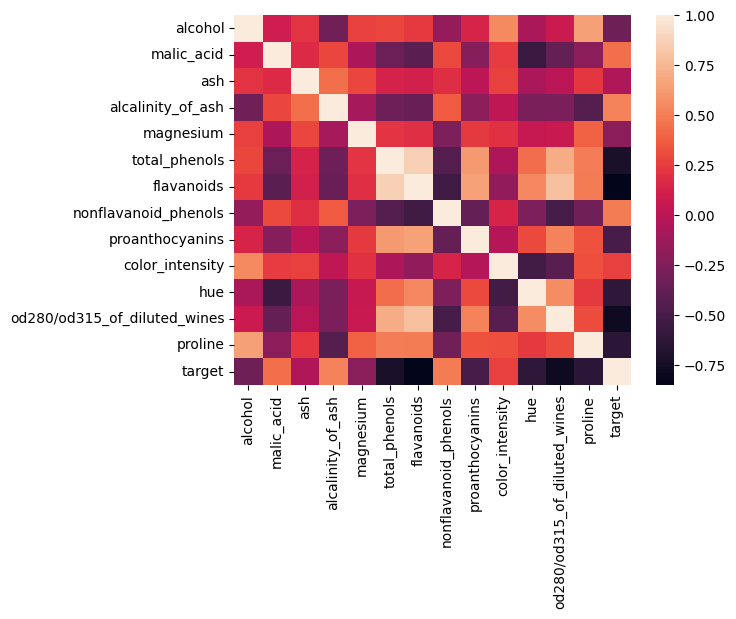

In [9]:
import seaborn as sns

sns.heatmap(df.corr())

어떤 성분끼리 상관관계가 높은지 확인.

flavanoids와 total_phenols는 양의 상관관계가 높음

<Axes: xlabel='target', ylabel='alcohol'>

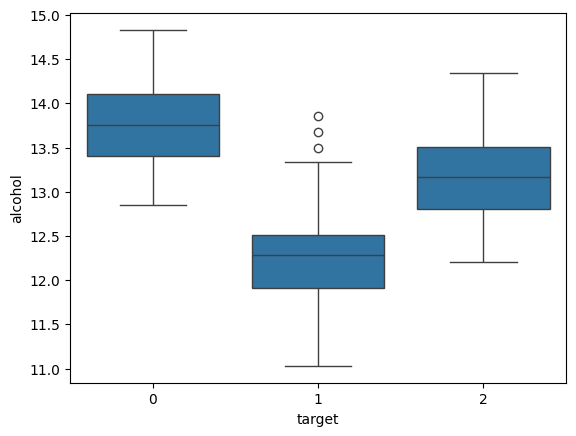

In [10]:
sns.boxplot(x='target', y='alcohol', data=df)

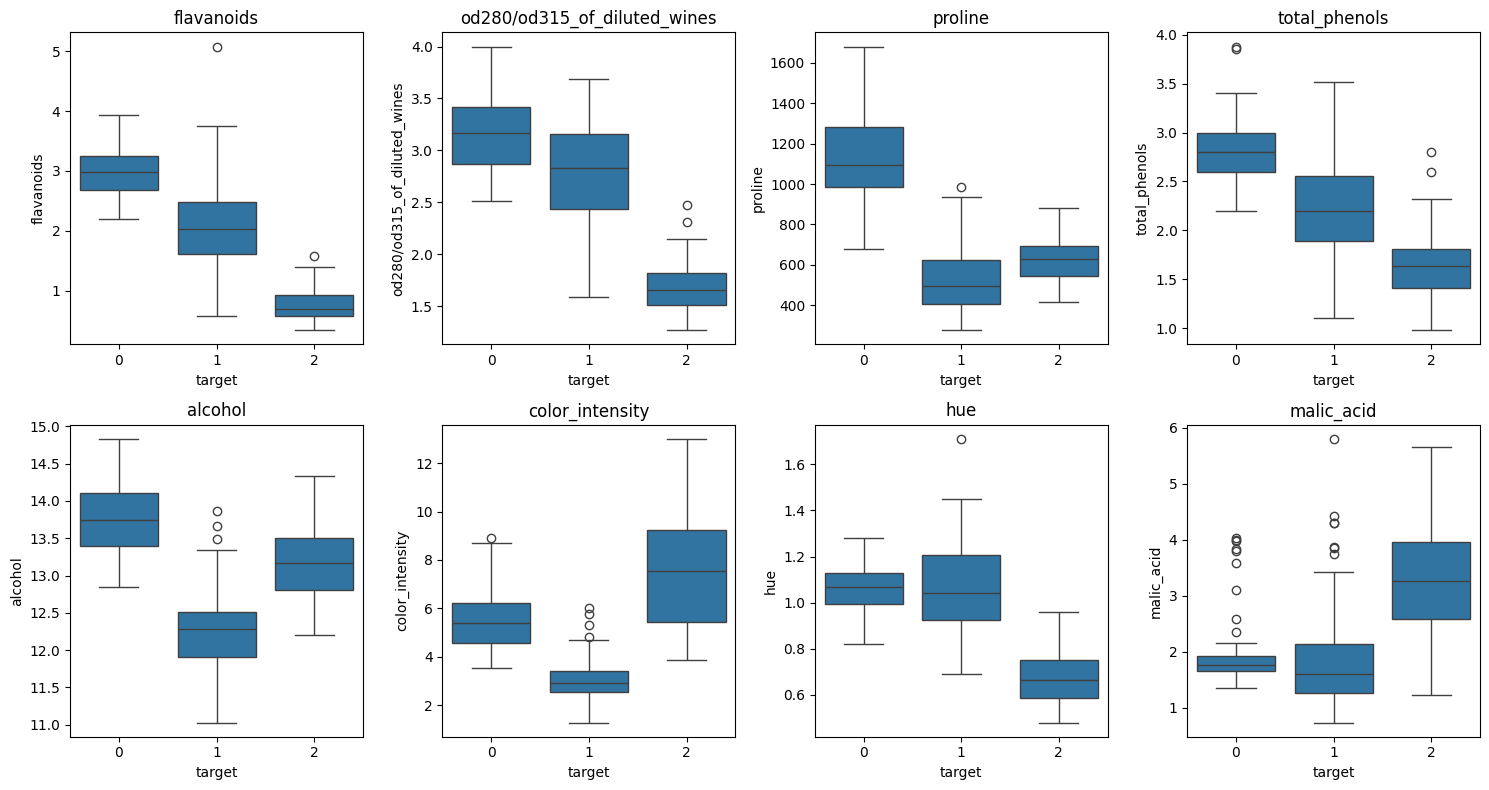

In [11]:
import matplotlib.pyplot as plt

key_features = [
    'flavanoids',
    'od280/od315_of_diluted_wines',
    'proline',
    'total_phenols',
    'alcohol',
    'color_intensity',
    'hue',
    'malic_acid'
]

fig, axes = plt.subplots(2, 4, figsize=(15, 8))
for idx, col in enumerate(key_features):
  row, c = divmod(idx, 4)
  sns.boxplot(x='target', y=col, data=df, ax=axes[row, c])
  axes[row, c].set_title(col)

plt.tight_layout()
plt.show()

앞선 상관계수에 따라 품종 구분에 가장 결정적인 변수 (flavanoids, od280/od315_of_diluted_wines, proline, total_phenols)과 감각적 특성(alcohol, color_intensity, malic_acid, hue) 사용


**품종 구분에 가장 결정적인 변수**
*   flavanoids: 플라보노이드, 떫은맛과 항산화 성분
*   od280/od315_of_diluted_wines: 희석 와인의 흡광도 / 와인의 농도 및 숙성도 지표
*   proline: 아미노산의 일종, 감칠맛과 바디감
*   total_phenols: 총 페놀 함량, 떫은맛과 바디감


**감각적 특성**
*   alcohol: 알코올
*   color_intensity: 색의 강도
*   hue: 색조 / 빛깔
*   malic_acid: 산미(사과산)



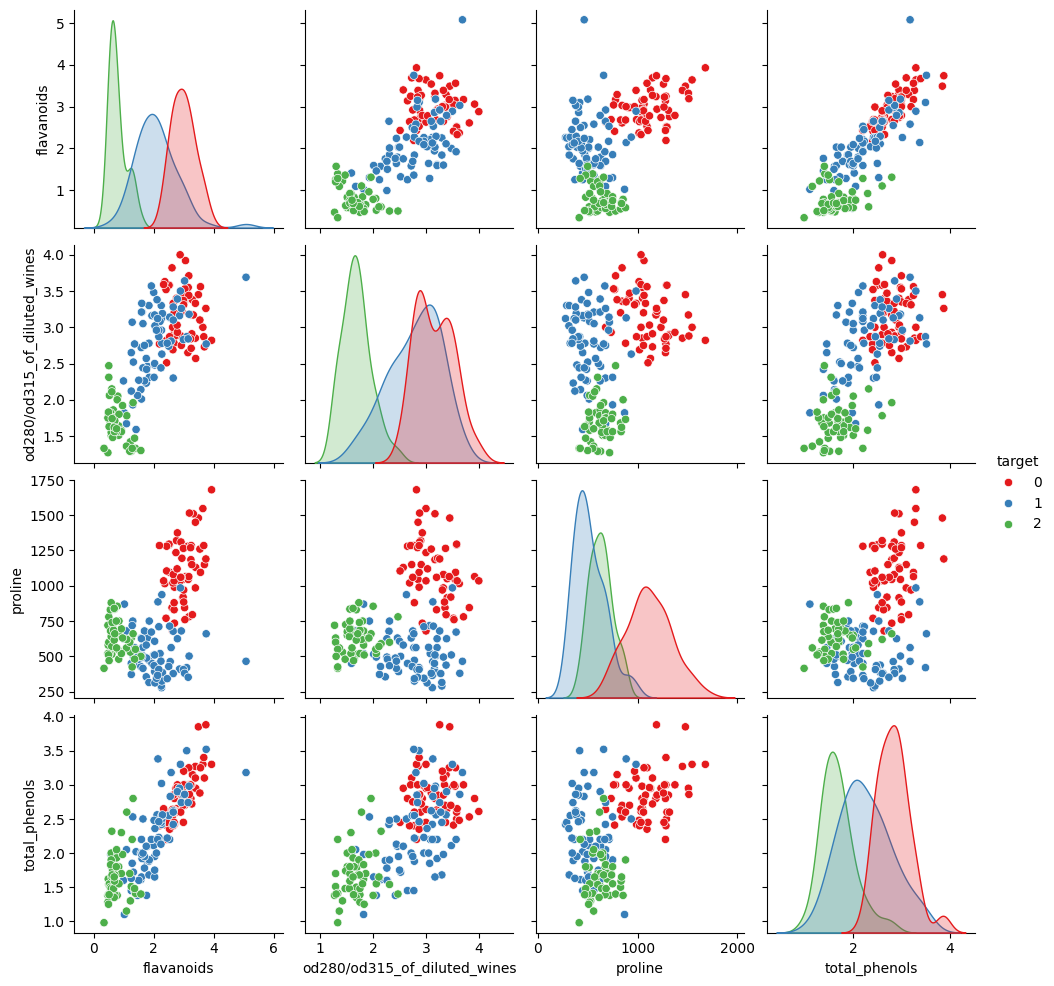

In [12]:
pairplot_cols = [
    'flavanoids',
    'od280/od315_of_diluted_wines',
    'proline',
    'total_phenols',
    'target'
]

sns.pairplot(df[pairplot_cols], hue='target', palette='Set1')
plt.show()

산점도 보면 각 품종이 섞여있기보단 군집을 형성하고 있음을 볼 수 있음

빨간색(class0)이 가장 높은 수치를 보임
초록색(class2)이 가장 낮은 수치를 보임
파란색(class1)은 초록색과 빨간색의 중간에 위치

산점도를 보면 어느 class에 이상치가 어떻게 있는지 확인

# 데이터 분할

In [13]:
from sklearn.model_selection import train_test_split

x_train, x_val, y_train, y_val = train_test_split(
    x, y, test_size=0.2, stratify=y, random_state=42
)

In [14]:
x_train_mean = x_train.mean(axis=0)
x_train_std = x_train.std(axis=0)
x_train_s = (x_train - x_train_mean) / x_train_std
x_val_s = (x_val - x_train_mean) / x_train_std

print('특성별 평균: ', x_train_s.mean(axis=0).round(2))
print('특성별 표준편차: ', x_train_s.std(axis=0).round(2))

특성별 평균:  [ 0. -0.  0.  0.  0. -0.  0. -0. -0.  0. -0.  0. -0.]
특성별 표준편차:  [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


# 주성분분석(PCA)

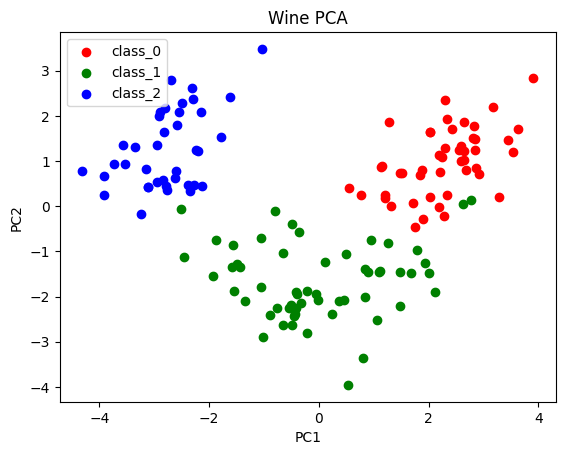

설명된 분산 비율: [0.358 0.193]
총 설명력: 0.551


In [15]:
from sklearn.decomposition import PCA
import numpy as np

pca = PCA(n_components=2)
X2D = pca.fit_transform(x_train_s)

colors = ['red', 'green', 'blue']
for i, j in enumerate(np.unique(y_train)):
  plt.scatter(X2D[y_train == j, 0], X2D[y_train == j, 1],
              color = colors[i], label = f'class_{j}')

plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('Wine PCA')
plt.legend()
plt.show()

print('설명된 분산 비율:', pca.explained_variance_ratio_.round(3))
print('총 설명력:', pca.explained_variance_ratio_.sum().round(3))

In [16]:
import pandas as pd

loadings = pd.DataFrame(
    pca.components_.T,
    columns=['PC1', 'PC2'],
    index=wine.feature_names
)

print(loadings.reindex(loadings['PC1'].abs().sort_values(ascending=False).index).round(3))

                                PC1    PC2
flavanoids                    0.430 -0.003
total_phenols                 0.394  0.076
od280/od315_of_diluted_wines  0.383 -0.170
proanthocyanins               0.313  0.011
hue                           0.297 -0.298
nonflavanoid_phenols         -0.291  0.021
proline                       0.290  0.358
malic_acid                   -0.234  0.223
alcalinity_of_ash            -0.224 -0.039
magnesium                     0.152  0.296
alcohol                       0.144  0.487
color_intensity              -0.096  0.524
ash                           0.007  0.312
